In [2]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report,
                             confusion_matrix, precision_recall_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.features import RAW_FEATURES, build_features, clean_data

SEED = 42
PROJECT_DIR = Path.cwd()
RAW_PATH = PROJECT_DIR / 'raw.csv'
MODEL_DIR = PROJECT_DIR / 'models'
if not RAW_PATH.exists():
    raise FileNotFoundError('Jalankan notebook dari folder repositori yang berisi raw.csv.')
print('Folder proyek:', PROJECT_DIR)
print('scikit-learn:', sklearn.__version__)

Folder proyek: c:\Users\ASUS\OneDrive\Documents\PROJEK ML GIAN & GANESH
scikit-learn: 1.9.1


In [2]:
df_raw = pd.read_csv(RAW_PATH)
required = set(RAW_FEATURES + ['waktu_produksi', 'cacat'])
missing_columns = required - set(df_raw.columns)
if missing_columns:
    raise ValueError(f'Kolom wajib tidak ditemukan: {sorted(missing_columns)}')

display(df_raw.head())
print('Ukuran awal:', df_raw.shape)
print('Duplikat penuh:', int(df_raw.duplicated().sum()))
print('Nilai kosong per kolom:')
display(df_raw.isna().sum().to_frame('jumlah_kosong'))
print('Distribusi target mentah:')
display(df_raw['cacat'].value_counts(dropna=False).to_frame('jumlah'))

,waktu_produksi,mesin,shift,bahan,suhu_leleh_C,suhu_cetakan_C,tekanan_injeksi_bar,kecepatan_injeksi_mm_s,waktu_pendinginan_s,waktu_siklus_s,kelembaban_bahan_pct,cacat
0,2026-03-01 00:12:45,IM-02,siang,PC,302.0,74.2,1053.0,68.6,15.1,27.5,0.088,0
1,2026-03-01 00:14:38,IM-01,pagi,P.P,219.6,40.1,1143.0,89.2,28.7,39.8,0.021,0
2,2026-03-01 00:19:00,IM-01,siang,ABS,230.6,67.7,945.0,89.2,15.2,29.2,0.046,0
3,2026-03-01 00:53:09,IM-01,malam,ABS,245.0,64.0,905.0,88.4,12.0,25.0,0.027,0
4,2026-03-01 01:07:19,IM-03,siang,PP,242.5,33.2,908.0,76.5,22.5,38.7,0.011,0


Ukuran awal: (25350, 12)
Duplikat penuh: 350
Nilai kosong per kolom:


,jumlah_kosong
waktu_produksi,0
mesin,0
shift,0
bahan,0
suhu_leleh_C,0
suhu_cetakan_C,0
tekanan_injeksi_bar,0
kecepatan_injeksi_mm_s,0
waktu_pendinginan_s,257
waktu_siklus_s,0


Distribusi target mentah:


,jumlah
cacat,
0,23371
1,1979


Rentang waktu: 2026-03-01 00:12:45 s.d. 2026-06-28 23:45:48
Proporsi cacat:


,proporsi
cacat,
0,0.921933
1,0.078067


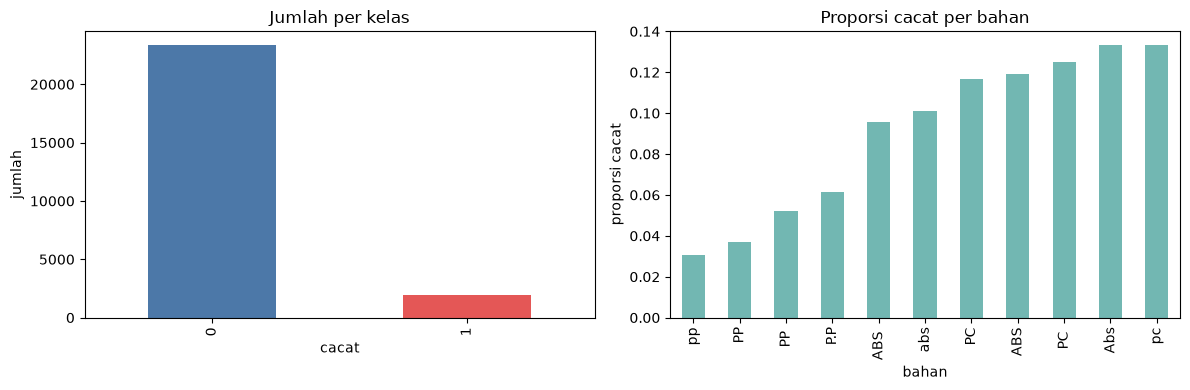

In [3]:
eda = df_raw.copy()
eda['waktu_produksi'] = pd.to_datetime(eda['waktu_produksi'], errors='coerce')
print('Rentang waktu:', eda['waktu_produksi'].min(), 's.d.', eda['waktu_produksi'].max())
print('Proporsi cacat:')
display(eda['cacat'].value_counts(normalize=True, dropna=False).rename('proporsi').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
eda['cacat'].value_counts(dropna=False).sort_index().plot.bar(ax=axes[0], color=['#4c78a8', '#e45756'])
axes[0].set(title='Jumlah per kelas', xlabel='cacat', ylabel='jumlah')
eda.groupby('bahan', dropna=False)['cacat'].mean().sort_values().plot.bar(ax=axes[1], color='#72b7b2')
axes[1].set(title='Proporsi cacat per bahan', xlabel='bahan', ylabel='proporsi cacat')
plt.tight_layout()
plt.show()

In [4]:
df = clean_data(df_raw).drop_duplicates().reset_index(drop=True)
df['cacat'] = pd.to_numeric(df['cacat'], errors='coerce')
df = df[df['cacat'].isin([0, 1])].copy()
df['cacat'] = df['cacat'].astype(int)
if df.empty:
    raise ValueError('Tidak ada baris dengan target cacat bernilai 0 atau 1 setelah pembersihan.')

train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df['cacat'], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['cacat'], random_state=SEED
)
for name, part in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    print(f'{name:10s}: n={len(part):,}, cacat={part.cacat.mean():.3%}')

train     : n=17,500, cacat=7.760%
validation: n=3,750, cacat=7.760%
test      : n=3,750, cacat=7.760%


In [5]:
CAT_COLS = ['mesin', 'shift', 'bahan']
NUM_RAW_COLS = [c for c in RAW_FEATURES if c not in CAT_COLS]

def make_preprocessor(numeric_cols, categorical_cols, dense=False):
    return ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), numeric_cols),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore',
                                                   sparse_output=not dense))]), categorical_cols),
    ])

X_train_raw = train_df[RAW_FEATURES]
y_train = train_df['cacat']
X_val_raw = val_df[RAW_FEATURES]
y_val = val_df['cacat']

baseline = Pipeline([
    ('prep', make_preprocessor(NUM_RAW_COLS, CAT_COLS)),
    ('model', LogisticRegression(max_iter=1000, class_weight=None, random_state=SEED)),
])
baseline.fit(X_train_raw, y_train)
val_prob_baseline = baseline.predict_proba(X_val_raw)[:, 1]
val_ap_baseline = average_precision_score(y_val, val_prob_baseline)
print(f'Baseline Logistic Regression — validation PR-AUC/AP: {val_ap_baseline:.4f}')

Baseline Logistic Regression — validation PR-AUC/AP: 0.5140


In [6]:
DROP_FROM_MODEL = ['waktu_produksi', 'cacat']
X_train_feat = build_features(train_df).drop(columns=DROP_FROM_MODEL, errors='ignore')
X_val_feat = build_features(val_df).drop(columns=DROP_FROM_MODEL, errors='ignore')
feature_cols = list(X_train_feat.columns)
if list(X_val_feat.columns) != feature_cols:
    raise ValueError('Kolom/urutan fitur validation berbeda dari train.')
cat_feat_cols = [c for c in CAT_COLS if c in feature_cols]
num_feat_cols = [c for c in feature_cols if c not in cat_feat_cols]

candidate = Pipeline([
    ('prep', make_preprocessor(num_feat_cols, cat_feat_cols, dense=True)),
    ('model', HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.05, max_depth=6, random_state=SEED
    )),
])
candidate.fit(X_train_feat, y_train)
val_prob = candidate.predict_proba(X_val_feat)[:, 1]
val_ap = average_precision_score(y_val, val_prob)
print(f'Baseline validation PR-AUC/AP: {val_ap_baseline:.4f}')
print(f'Kandidat validation PR-AUC/AP: {val_ap:.4f}')

Baseline validation PR-AUC/AP: 0.5140
Kandidat validation PR-AUC/AP: 0.6720


,threshold,TN,FP,FN,TP,total_cost_idr
2938,0.049212,2884,575,29,262,28875000
2937,0.049092,2883,576,29,262,28900000
2936,0.049085,2882,577,29,262,28925000
2935,0.049076,2881,578,29,262,28950000
2934,0.048920,2880,579,29,262,28975000
2933,0.048884,2879,580,29,262,29000000
2932,0.048652,2878,581,29,262,29025000
2931,0.048648,2877,582,29,262,29050000
2930,0.048511,2876,583,29,262,29075000
2929,0.048510,2875,584,29,262,29100000


Threshold terpilih: 0.0492; estimasi biaya validation: Rp28,875,000


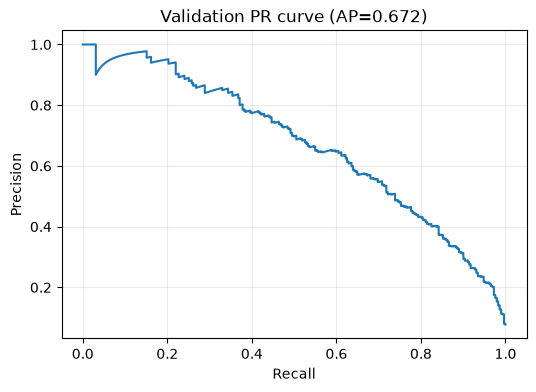

In [7]:
COST_FN = 500_000
COST_FP = 25_000
thresholds = np.unique(np.r_[np.linspace(0.01, 0.80, 500), val_prob])
rows = []
for threshold in thresholds:
    pred = (val_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    rows.append((threshold, int(tn), int(fp), int(fn), int(tp), int(fn * COST_FN + fp * COST_FP)))
threshold_table = pd.DataFrame(rows, columns=['threshold', 'TN', 'FP', 'FN', 'TP', 'total_cost_idr'])
best = threshold_table.sort_values(['total_cost_idr', 'threshold'], ascending=[True, False]).iloc[0]
BEST_THRESHOLD = float(best['threshold'])
display(threshold_table.nsmallest(10, 'total_cost_idr'))
print(f'Threshold terpilih: {BEST_THRESHOLD:.4f}; estimasi biaya validation: Rp{best.total_cost_idr:,.0f}')

precision, recall, pr_thresholds = precision_recall_curve(y_val, val_prob)
plt.figure(figsize=(6, 4))
plt.plot(recall, precision)
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title(f'Validation PR curve (AP={val_ap:.3f})')
plt.grid(alpha=0.25); plt.show()

In [8]:
X_test_feat = build_features(test_df).drop(columns=DROP_FROM_MODEL, errors='ignore')
y_test = test_df['cacat']
if list(X_test_feat.columns) != feature_cols:
    raise ValueError('Kolom/urutan fitur test berbeda dari train.')

test_prob = candidate.predict_proba(X_test_feat)[:, 1]
test_pred = (test_prob >= BEST_THRESHOLD).astype(int)
test_ap = average_precision_score(y_test, test_prob)
tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()
test_cost = int(fn * COST_FN + fp * COST_FP)
no_model_cost = int(y_test.sum() * COST_FN)
print(f'Test PR-AUC/AP: {test_ap:.4f}')
print(f'TN={tn:,}, FP={fp:,}, FN={fn:,}, TP={tp:,}')
print(f'Biaya keputusan model: Rp{test_cost:,.0f}')
print(f'Biaya jika semua komponen dilepas tanpa penyaringan: Rp{no_model_cost:,.0f}')
print(classification_report(y_test, test_pred, zero_division=0))

Test PR-AUC/AP: 0.6669
TN=2,885, FP=574, FN=39, TP=252
Biaya keputusan model: Rp33,850,000
Biaya jika semua komponen dilepas tanpa penyaringan: Rp145,500,000
              precision    recall  f1-score   support

           0       0.99      0.83      0.90      3459
           1       0.31      0.87      0.45       291

    accuracy                           0.84      3750
   macro avg       0.65      0.85      0.68      3750
weighted avg       0.93      0.84      0.87      3750



In [9]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(candidate, MODEL_DIR / 'model.joblib')
metadata = {
    'model_type': 'HistGradientBoostingClassifier',
    'sklearn_version': sklearn.__version__,
    'seed': SEED,
    'split': {'train': 0.70, 'validation': 0.15, 'test': 0.15},
    'features': feature_cols,
    'threshold': BEST_THRESHOLD,
    'metrics': {
        'validation_pr_auc_baseline': float(val_ap_baseline),
        'validation_pr_auc_final': float(val_ap),
        'test_pr_auc_final': float(test_ap),
        'test_confusion_matrix': {'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)},
        'test_cost_idr': test_cost,
    },
    'business_cost_assumption': {'FN_idr': COST_FN, 'FP_idr': COST_FP},
}
with (MODEL_DIR / 'metadata.json').open('w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)
print('Tersimpan:', MODEL_DIR / 'model.joblib')
print('Tersimpan:', MODEL_DIR / 'metadata.json')

Tersimpan: C:\Users\ASUS\OneDrive\Documents\PROJEK ML GIAN & GANESH\models\model.joblib
Tersimpan: C:\Users\ASUS\OneDrive\Documents\PROJEK ML GIAN & GANESH\models\metadata.json
